# Etapa 6 · Baselines e avaliação

Dois baselines servem de régua para o BERTimbau e o MariTalk:

1. **Trivial:** prevê sempre a nota mais comum do treino. Mostra por que o MAE e a acurácia com tolerância sozinhos enganam.
2. **TF-IDF + Ridge:** n-gramas de palavras (1 e 2) com pesos TF-IDF e regressão linear com regularização L2. O `alpha` é escolhido **só no dev**.

Todas as métricas saem de `src/avaliacao.py` (MAE, QWK, acurácia exata e acurácia com tolerância ±80 por competência / ±100 no total), sempre no **mesmo conjunto de redações** para todos os modelos. Os testes do avaliador estão em `tests/test_avaliacao.py`.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ / "src"))
import pandas as pd
from IPython.display import Image, Markdown, display
import baseline_tfidf, avaliacao

## 6.1 Treinar os baselines e escolher o alpha no dev

In [2]:
info = baseline_tfidf.executar(RAIZ / "data", RAIZ / "results")
print("baseline trivial (moda do treino):", info["trivial"]["moda_treino"])
busca = pd.DataFrame(info["tfidf"]["busca_alpha_dev"]).round(4)
print("alpha escolhido pelo QWK médio no dev:", info["tfidf"]["alpha_escolhido"])
busca

baseline trivial (moda do treino): {'c1': 120, 'c2': 120, 'c3': 120, 'c4': 120, 'c5': 120}
alpha escolhido pelo QWK médio no dev: 0.3


,alpha,qwk_medio_dev,mae_medio_dev
0,0.01,0.4705,24.2432
1,0.03,0.4685,24.1783
2,0.10,0.4687,23.8703
3,0.30,0.4710,23.1489
4,1.00,0.4492,22.6869
5,3.00,0.3832,23.5056
6,10.00,0.2647,25.5968
7,30.00,0.1463,27.7852


O melhor `alpha` pelo QWK (0,3) não é o melhor pelo MAE (1): as duas métricas medem coisas diferentes. Escolhemos pelo QWK, a métrica principal, porque ele mede se o modelo **ordena** as redações como os corretores, e não só se fica perto da média. Abaixo de 0,3 o QWK estabiliza, então o ótimo está dentro da grade testada.

## 6.2 Avaliação no teste

O avaliador lê todos os `results/preds_*.csv` disponíveis. Por enquanto só existem os baselines; a tabela final é regenerada quando `preds_bertimbau.csv` e `preds_maritalk.csv` chegarem.

In [3]:
import os
os.chdir(RAIZ)   # caminhos relativos à raiz do projeto, como na linha de comando
avaliacao.main(["--gabarito", "data/test.csv", "--preds", "results/preds_*.csv",
                "--saida", "results/tabela_final.csv", "--figuras", "results/figuras"])

n = 985 redações · modelos: trivial, tfidf

QWK:
alvo               c1     c2     c3     c4     c5  média c1–c5  total
Trivial (moda)  0.000  0.000  0.000  0.000  0.000        0.000  0.000
TF-IDF + Ridge  0.461  0.463  0.457  0.594  0.539        0.503  0.623

MAE:
alvo              c1    c2    c3    c4    c5  média c1–c5  total
Trivial (moda)  24.2  31.1  25.6  35.0  38.5         30.9  144.6
TF-IDF + Ridge  16.0  21.8  21.0  22.6  28.2         21.9   94.1

Acc_tol:
alvo               c1     c2     c3     c4     c5  média c1–c5  total
Trivial (moda)  0.988  0.983  0.971  0.968  0.921        0.966  0.425
TF-IDF + Ridge  0.990  0.987  0.984  0.978  0.969        0.981  0.646

Tabela: results\tabela_final.csv e results\tabela_final.md · figuras: results/figuras (competência mais difícil: C3)


In [4]:
display(Markdown((RAIZ / "results/tabela_final.md").read_text(encoding="utf-8")))

Conjunto: data/test.csv · n = 985 redações

## QWK

|                |    c1 |    c2 |    c3 |    c4 |    c5 |   média c1–c5 |   total |
|:---------------|------:|------:|------:|------:|------:|--------------:|--------:|
| Trivial (moda) | 0     | 0     | 0     | 0     | 0     |         0     |   0     |
| TF-IDF + Ridge | 0.461 | 0.463 | 0.457 | 0.594 | 0.539 |         0.503 |   0.623 |

## MAE

|                |   c1 |   c2 |   c3 |   c4 |   c5 |   média c1–c5 |   total |
|:---------------|-----:|-----:|-----:|-----:|-----:|--------------:|--------:|
| Trivial (moda) | 24.2 | 31.1 | 25.6 | 35   | 38.5 |          30.9 |   144.6 |
| TF-IDF + Ridge | 16   | 21.8 | 21   | 22.6 | 28.2 |          21.9 |    94.1 |

## Acc_exata

|                |    c1 |    c2 |    c3 |    c4 |    c5 |   média c1–c5 |   total |
|:---------------|------:|------:|------:|------:|------:|--------------:|--------:|
| Trivial (moda) | 0.468 | 0.368 | 0.466 | 0.383 | 0.339 |         0.405 |   0.106 |
| TF-IDF + Ridge | 0.644 | 0.532 | 0.548 | 0.524 | 0.468 |         0.543 |   0.165 |

## Acc_tol

|                |    c1 |    c2 |    c3 |    c4 |    c5 |   média c1–c5 |   total |
|:---------------|------:|------:|------:|------:|------:|--------------:|--------:|
| Trivial (moda) | 0.988 | 0.983 | 0.971 | 0.968 | 0.921 |         0.966 |   0.425 |
| TF-IDF + Ridge | 0.99  | 0.987 | 0.984 | 0.978 | 0.969 |         0.981 |   0.646 |



**Por que o MAE sozinho engana:** o baseline trivial acerta mais de 96% das notas por competência dentro da tolerância de ±80 e erra em média só ~31 pontos, porque quase todas as notas estão em 120 ou 160. Mas o QWK dele é **0**: ele não distingue uma redação boa de uma ruim.

## 6.3 Gráficos

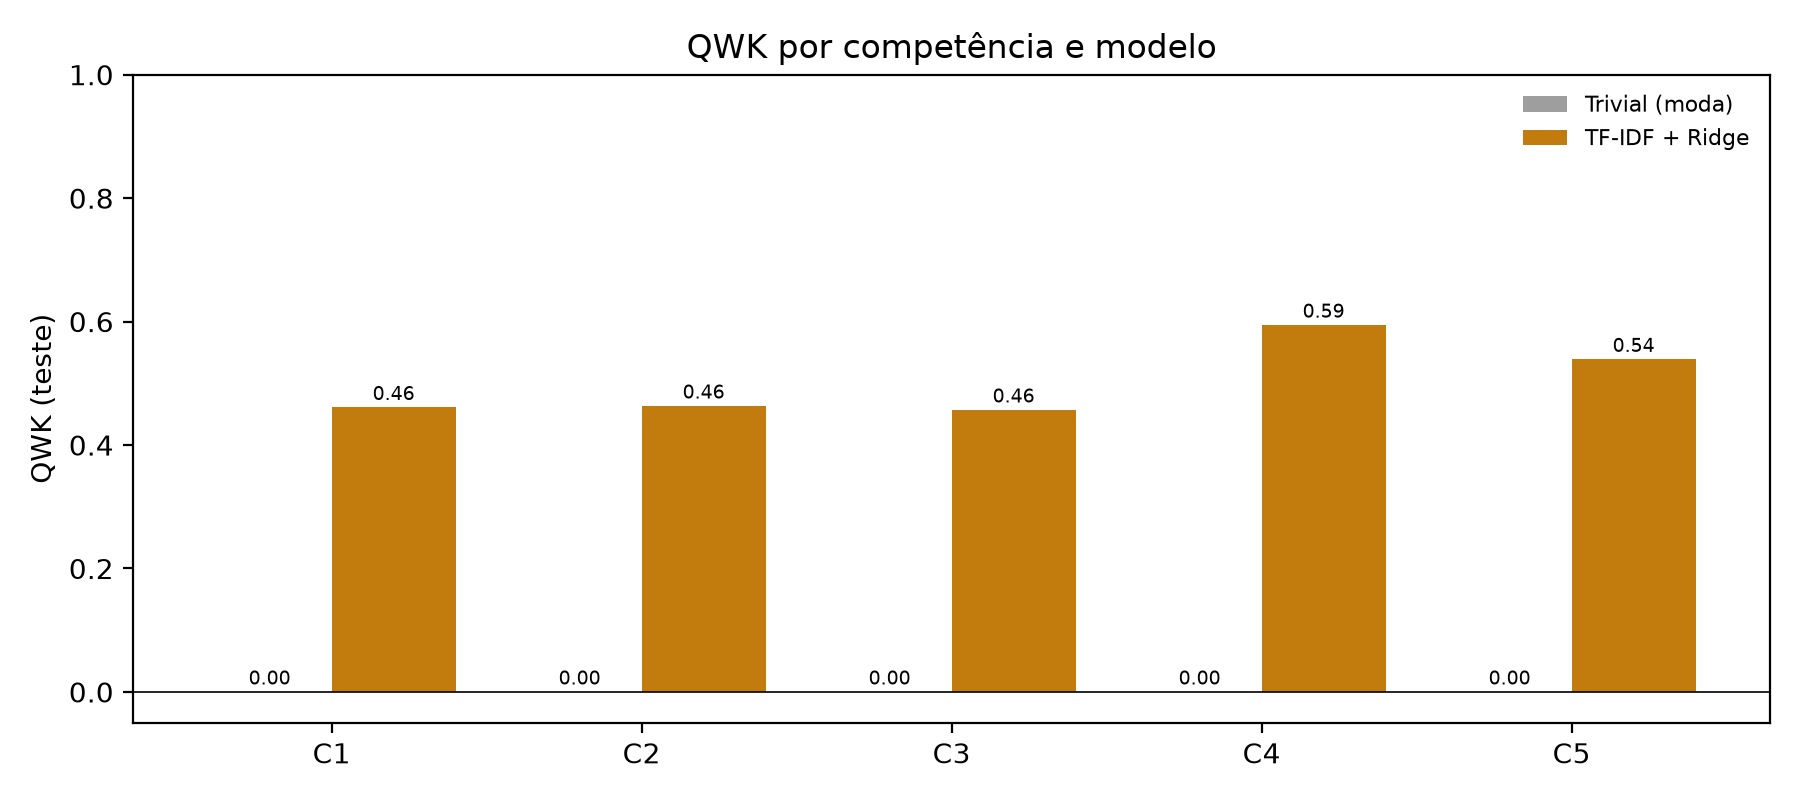

In [5]:
display(Image(str(RAIZ / "results/figuras/qwk_por_competencia.png"), width=750))

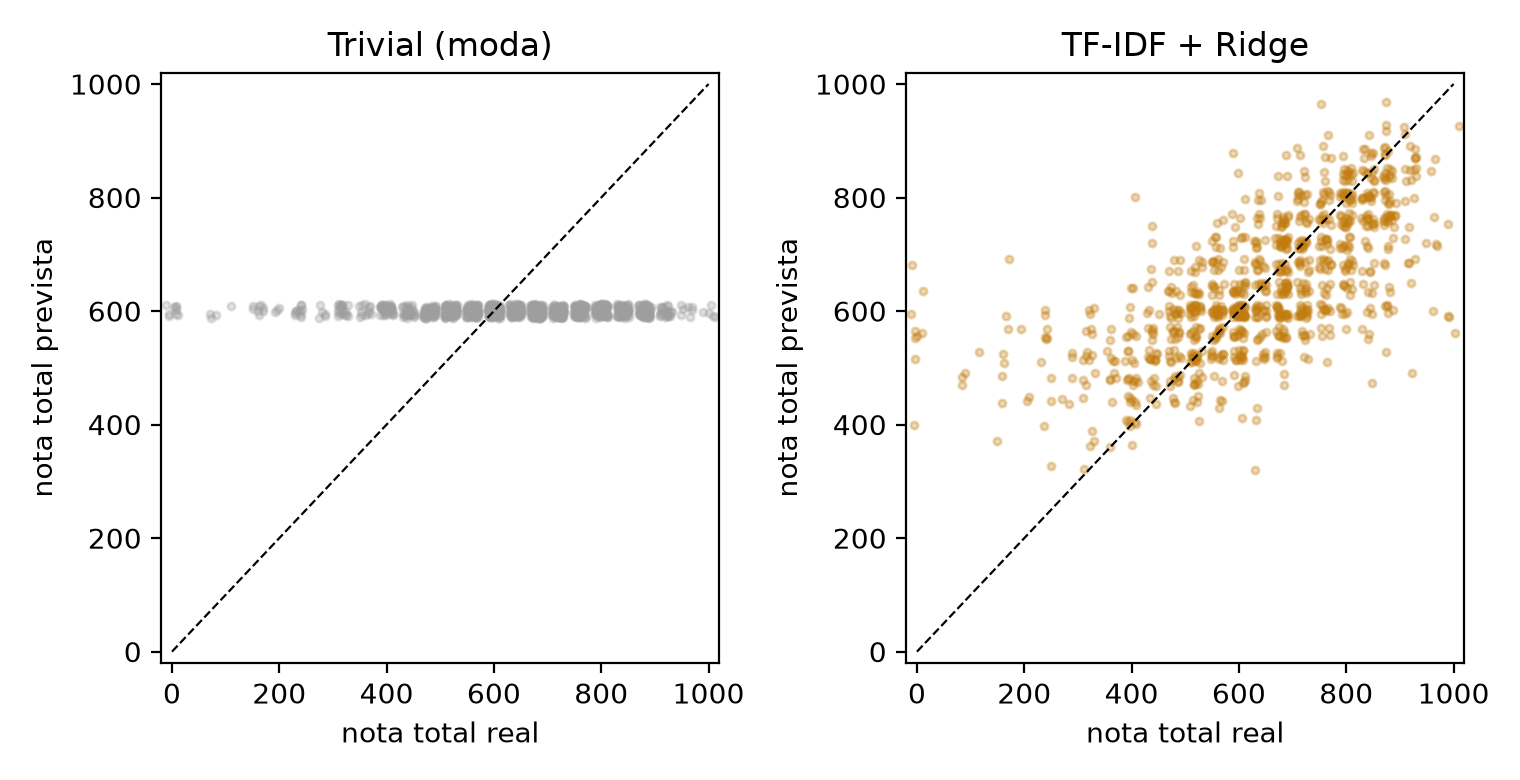

In [6]:
display(Image(str(RAIZ / "results/figuras/real_vs_previsto_total.png"), width=750))

competência mais difícil (menor QWK médio): C3


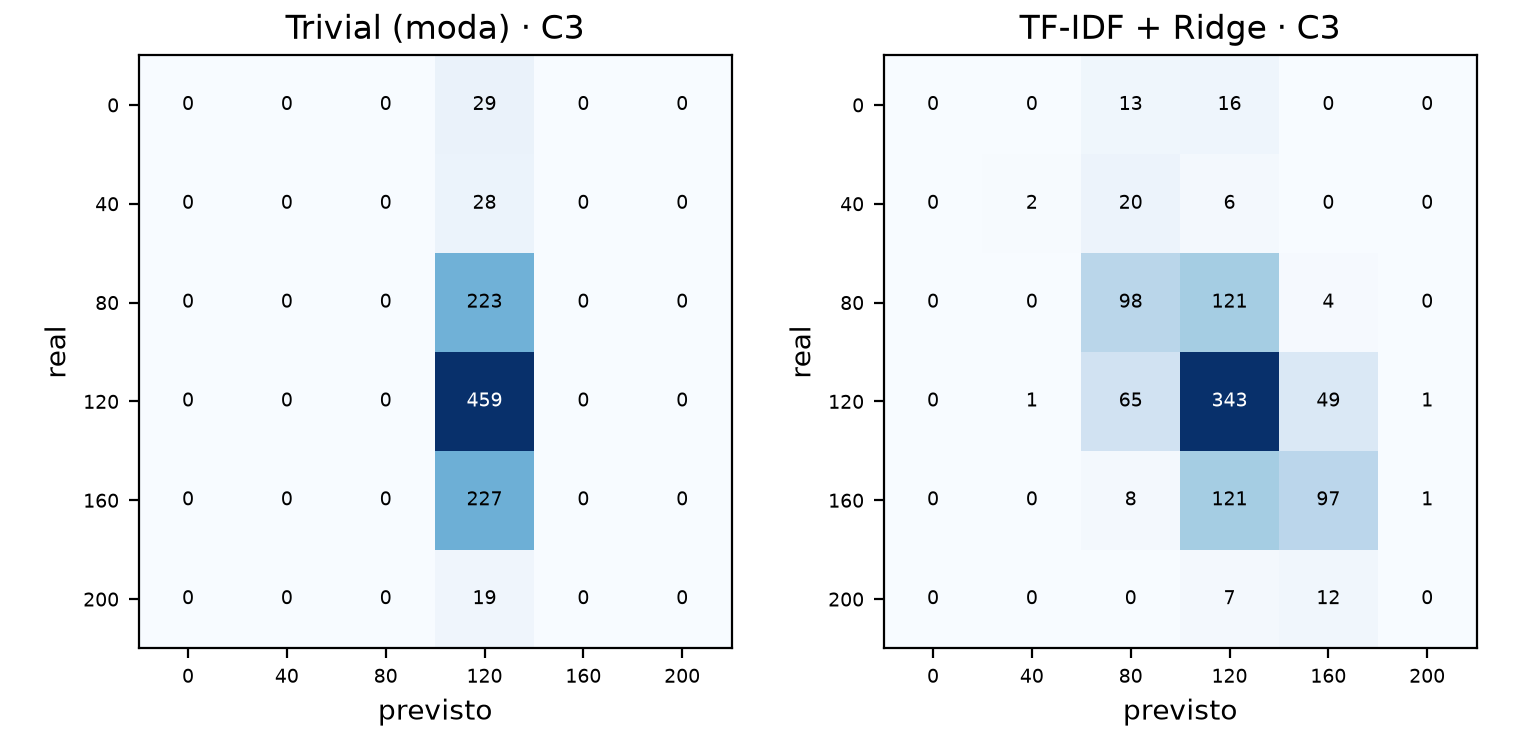

In [7]:
tab = pd.read_csv(RAIZ / "results/tabela_final.csv")
dificil = (tab[tab.alvo.str.startswith("c")].groupby("alvo")["QWK"].mean().idxmin())
print("competência mais difícil (menor QWK médio):", dificil.upper())
display(Image(str(RAIZ / f"results/figuras/confusao_{dificil}.png"), width=750))